# Bước 3 — Phân tích Khám phá Dữ liệu (EDA) & Trực quan hóa

**Đề tài:** Phân tích & dự báo giá thuê nhà trọ/căn hộ **theo khu vực** — *Nhập môn Khoa học Dữ liệu (IT4142)*

Notebook thực hiện **Bước 3** trong vòng đời Khai phá Tri thức (Slide L4–L6): thống kê
mô tả, phân tích đơn biến / đa biến, trực quan hóa, phân cụm K-Means và giảm chiều PCA —
*mọi phân tích đều hướng tới mục tiêu cuối: hiểu yếu tố nào chi phối **giá thuê** để phục vụ
mô hình hồi quy ở Bước 4.*

**Dữ liệu đầu vào (kết quả Bước 2 — notebook `02_data_cleaning.ipynb`):**
`v2/data/processed/rental_data_clean.csv` — giá tính bằng **triệu VNĐ/tháng**.

---
### Hai loại biểu đồ trong notebook (hybrid)
| Loại | Thư viện | Mục đích |
|---|---|---|
| 🖼️ **Tĩnh** | seaborn / matplotlib | Lưu PNG độ phân giải cao → nhúng báo cáo PDF |
| 🖱️ **Tương tác** | plotly | Hover/zoom khám phá trong notebook (+ PNG & HTML kèm theo) |

> **Điều chỉnh so với tài liệu hướng dẫn:** Bộ dữ liệu thực tế **không có** sẵn các cột
> `district`, `city`, `dtcenter`. Notebook tự **trích xuất `city`/`district` từ `full_address`**
> và thay biến `dtcenter` (cần geocoding — ngoài phạm vi) bằng các biến phái sinh
> `n_features` (tổng tiện ích) và `price_per_m2` (đơn giá/m²).
>
> 🔗 **Liên hệ Bước 2:** việc **kiểm toán nguồn gốc 12 cờ tiện ích** (phát hiện 7 cờ bị
> *điền ngẫu nhiên* khi gộp nguồn) đã được làm ở notebook 02 v2 — tại đây ta chỉ **mô tả
> dữ liệu như-nó-là** và nhắc lại kết luận đó ở mục 7 & 9.2.


## 0. Thiết lập môi trường & hệ thống màu sắc nhất quán

In [1]:
import warnings, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

warnings.filterwarnings("ignore")

# ---------- Bảng màu thương hiệu dùng xuyên suốt notebook ----------
PALETTE   = ["#2D5BFF", "#00C2A8", "#FF8C42", "#E5446D", "#7B61FF", "#FFC857"]
SEQ_CMAP  = "crest"     # thang tuần tự (seaborn)
DIV_CMAP  = "vlag"      # thang phân kỳ (âm/dương)

# ---------- Style cho matplotlib / seaborn (biểu đồ tĩnh) ----------
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
sns.set_palette(sns.color_palette(PALETTE))
matplotlib.rcParams.update({
    "font.family": "DejaVu Sans",        # hỗ trợ dấu tiếng Việt
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "figure.facecolor": "white",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlepad": 12,
    "axes.labelsize": 11,
    "axes.edgecolor": "#555",
    "grid.alpha": 0.30,
})

# ---------- Template plotly đồng bộ màu/font (biểu đồ tương tác) ----------
pio.templates["btl"] = go.layout.Template(layout=dict(
    font=dict(family="DejaVu Sans, Arial", size=13, color="#1f2937"),
    colorway=PALETTE,
    title=dict(font=dict(size=18, color="#111827"), x=0.02, xanchor="left"),
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=75, r=40, t=70, b=60),
    xaxis=dict(showgrid=True, gridcolor="#ECECEC", zeroline=False, linecolor="#999"),
    yaxis=dict(showgrid=True, gridcolor="#ECECEC", zeroline=False, linecolor="#999"),
    hoverlabel=dict(font_size=12),
))
pio.templates.default = "plotly_white+btl"

# ---------- Đường dẫn (v2-local) ----------
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parents[1]                           # → .../btl_khdl
DATA  = ROOT / "v2" / "data" / "processed"           # đầu vào: sản phẩm Bước 2 (v2)
FIG   = ROOT / "v2" / "docs" / "eda"                 # PNG cho báo cáo
IHTML = FIG / "interactive"                          # HTML tương tác độc lập
FIG.mkdir(parents=True, exist_ok=True)
IHTML.mkdir(parents=True, exist_ok=True)

def save_mpl(fig, name):
    "Lưu figure matplotlib thành PNG cho báo cáo."
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight", facecolor="white")

def show_px(fig, name, w=1000, h=600):
    "Lưu PNG (báo cáo) + HTML (tương tác) rồi hiển thị plotly trong notebook."
    fig.update_layout(width=w, height=h)
    try:
        fig.write_image(str(FIG / f"{name}.png"), scale=2)      # cần kaleido
    except Exception as e:
        print("  (bỏ qua export PNG plotly:", e, ")")
    fig.write_html(str(IHTML / f"{name}.html"), include_plotlyjs="cdn")
    fig.show()

print("ROOT:", ROOT)
print("DATA ->", DATA)
print("PNG  ->", FIG)
print("HTML ->", IHTML)
print("seaborn", sns.__version__, "| plotly", pio.__version__ if hasattr(pio,'__version__') else "?")

ROOT: /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl
DATA -> /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/data/processed
PNG  -> /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/docs/eda
HTML -> /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/docs/eda/interactive
seaborn 0.13.2 | plotly ?


## 1. Nạp dữ liệu cho thuê

In [2]:
rental = pd.read_csv(DATA / "rental_data_clean.csv", low_memory=False)
# Bỏ ký tự BOM nếu có ở tên cột đầu tiên
rental.columns = [c.lstrip("﻿") for c in rental.columns]

feature_cols = [c for c in rental.columns if c.startswith("feature_")]
print(f"Cho thuê (rental): {rental.shape[0]:,} dòng × {rental.shape[1]} cột")
print(f"Số cột tiện ích (feature_*): {len(feature_cols)}")
print("Biến số chính:", ["price", "area", "bedrooms", "bathrooms"])
rental.head(3)

Cho thuê (rental): 133,586 dòng × 21 cột
Số cột tiện ích (feature_*): 12
Biến số chính: ['price', 'area', 'bedrooms', 'bathrooms']


,source,detail_link,price,area,full_address,posted_date,description,bedrooms,bathrooms,feature_Đầy đủ nội thất,...,feature_Có kệ bếp,feature_Có máy lạnh,feature_Có máy giặt,feature_Có tủ lạnh,feature_Có thang máy,feature_Không chung chủ,feature_Giờ giấc tự do,feature_Có bảo vệ 24/24,feature_Có hầm để xe,feature_Có nước nóng
0,phongtro123,https://phongtro123.com/cho-thue-phong-tro-khe...,3.1,20.0,"Ngõ 322 Đường Mỹ Đình, Phường Mỹ Đình 1, Quận ...","Thứ 3, 22:20 21/04/2026",Toà nhà mình có 7 phòng khép kin đang cho thuê...,4,1,1,...,1,1,1,0,0,1,1,0,1,1
1,phongtro123,https://phongtro123.com/khuong-ha-thanh-xuan-g...,1.2,20.0,"Số 1 Ngách 42 ngõ 29 Phố Khương Hạ, Phường Khư...","Thứ 2, 13:56 04/05/2026",Liên hệ cô Lưu chủ nhà trọ : 098 6491768\nNgác...,2,5,0,...,0,0,0,0,0,1,1,0,0,1
2,phongtro123,https://phongtro123.com/cho-thue-phong-2-9tr-t...,2.9,35.0,"Đường Vân Trì, Phường Minh Khai, Quận Bắc Từ L...","Chủ Nhật, 18:10 03/05/2026",CHO THUÊ PHÒNG TRỌ GIÁ RẺ – FULL NỘI THẤT – NH...,1,2,1,...,1,1,1,1,1,1,1,0,1,0


## 2. Trích xuất đặc trưng phục vụ EDA

| Biến phái sinh | Ý nghĩa |
|---|---|
| `city`, `district` | Tách từ `full_address` — phục vụ phân tích **theo khu vực** (lõi của đề tài) |
| `n_features` | Tổng số tiện ích → proxy mức độ đầy đủ tiện nghi |
| `price_per_m2` | Đơn giá/m² → so sánh khu vực công bằng hơn giá tuyệt đối |
| `log_price` | Log giá → kiểm tra/giảm độ lệch phải, hữu ích cho mô hình tuyến tính |

> Logic tách `city`/`district` ở đây **trùng khít** với mô-đun dùng chung train/serve của
> Bước 4 — đảm bảo không lệch train/serve.


In [3]:
PROVINCES = ["Hà Nội", "Hồ Chí Minh", "Đà Nẵng", "Bình Dương", "Hưng Yên",
             "Hải Phòng", "Quảng Ninh", "Khánh Hòa", "Đồng Nai", "Cần Thơ",
             "Bắc Ninh", "Hải Dương", "Nghệ An", "Thừa Thiên Huế", "Huế",
             "Bà Rịa", "Vũng Tàu", "Lâm Đồng", "Thanh Hóa", "Quảng Nam"]
_dist_re = re.compile(r"^(Quận|Huyện|Thị xã|Thành phố|TP)\s", re.IGNORECASE)

def parse_address(addr):
    parts = [p.strip() for p in str(addr).split(",") if p.strip()]
    city = None
    for p in reversed(parts):
        for prov in PROVINCES:
            if prov.lower() in p.lower():
                city = prov
                break
        if city:
            break
    if city is None and parts:
        city = parts[-1]
    district = next((p for p in parts if _dist_re.match(p)), None)
    return city, district

parsed = rental["full_address"].apply(parse_address)
rental["city"]         = parsed.map(lambda x: x[0])
rental["district"]     = parsed.map(lambda x: x[1])
rental["n_features"]   = rental[feature_cols].sum(axis=1)
rental["price_per_m2"] = rental["price"] / rental["area"]          # triệu/m²/tháng
rental["log_price"]    = np.log1p(rental["price"])

print("Top thành phố :", rental["city"].value_counts().head(5).to_dict())
print("Số quận/huyện riêng biệt:", rental["district"].nunique())
print("Thiếu district:", rental["district"].isna().sum(), "/", len(rental))
rental[["price", "area", "bedrooms", "bathrooms", "n_features",
        "price_per_m2", "city", "district"]].head()

Top thành phố : {'Hà Nội': 117574, 'Hồ Chí Minh': 11559, 'Đà Nẵng': 1411, 'Bình Dương': 358, 'Hưng Yên': 264}
Số quận/huyện riêng biệt: 352
Thiếu district: 2938 / 133586


,price,area,bedrooms,bathrooms,n_features,price_per_m2,city,district
0,3.1,20.0,4,1,8,0.155000,Hà Nội,Quận Nam Từ Liêm
1,1.2,20.0,2,5,3,0.060000,Hà Nội,Quận Thanh Xuân
2,2.9,35.0,1,2,10,0.082857,Hà Nội,Quận Bắc Từ Liêm
3,1.3,78.0,1,3,1,0.016667,Hà Nội,Quận Cầu Giấy
4,4.8,28.0,1,1,11,0.171429,Hà Nội,Quận Đống Đa


## 3. Tổng quan chất lượng dữ liệu

Trước khi phân tích, ta soi **nguồn gốc**, **giá trị thiếu** và **miền giá trị** —
đây là bước "hiểu dữ liệu" bắt buộc của EDA (John Tukey) và là nơi lộ ra các vấn đề
ảnh hưởng tới mô hình về sau.


### 3.1. Nguồn gốc dữ liệu (provenance) — *tương tác*

In [4]:
src = (rental["source"].value_counts()
       .rename_axis("source").reset_index(name="count"))
src["pct"] = (src["count"] / src["count"].sum() * 100).round(1)

fig = px.bar(src, x="count", y="source", orientation="h",
             text=src["pct"].map(lambda v: f"{v}%"),
             color="count", color_continuous_scale="Blues",
             title="Số bài đăng theo nguồn cào (các website cho thuê tích hợp ở Bước 2)")
fig.update_layout(yaxis=dict(categoryorder="total ascending"),
                  coloraxis_showscale=False, xaxis_title="Số bài đăng", yaxis_title="")
fig.update_traces(textposition="outside",
                  hovertemplate="<b>%{y}</b><br>%{x:,} bài (%{text})<extra></extra>")
show_px(fig, "01_source_distribution", w=950, h=520)

print(f"⚠️  Mất cân bằng nguồn: '{src.iloc[0]['source']}' chiếm "
      f"{src.iloc[0]['pct']}% toàn bộ dữ liệu → cần kiểm tra thiên lệch nguồn ở mục 9.2.")

⚠️  Mất cân bằng nguồn: 'chothuephongtro' chiếm 71.2% toàn bộ dữ liệu → cần kiểm tra thiên lệch nguồn ở mục 9.2.


### 3.2. Giá trị thiếu, miền giá trị & độ tin cậy các trường

In [5]:
miss = (rental.isna().mean() * 100).round(1)
miss = miss[miss > 0].sort_values(ascending=False)
print("=== Tỷ lệ thiếu (%) — chỉ các cột có thiếu ===")
print(miss.to_string() if len(miss) else "Không có cột nào thiếu trong các trường phân tích.")

print("\n=== Miền giá trị các biến số (sau lọc ở Bước 2) ===")
rng = rental[["price", "area", "bedrooms", "bathrooms"]].agg(["min", "max"]).T
rng.columns = ["min", "max"]
print(rng.to_string())

# Kiểm tra độ tin cậy posted_date (phát hiện ngày tương lai = sentinel cào)
d = pd.to_datetime(rental["posted_date"], errors="coerce")
fut = (d > pd.Timestamp("2026-06-06")).mean() * 100
print(f"\n⚠️  posted_date: {fut:.0f}% bản ghi có ngày trong TƯƠNG LAI "
      f"(giá trị mặc định khi cào) → KHÔNG dùng để phân tích xu hướng thời gian.")
print("ℹ️  price ≤ 17 và area ≤ 180 do Bước 2 đã LỌC ngưỡng (không phải clip) "
      "→ ngoại lệ cực đoan đã được loại, độ lệch còn lại ở mức nhẹ (xem mục 4).")

=== Tỷ lệ thiếu (%) — chỉ các cột có thiếu ===
detail_link    96.4
description    80.4
district        2.2

=== Miền giá trị các biến số (sau lọc ở Bước 2) ===
           min    max
price      0.5   17.0
area       8.0  180.0
bedrooms   0.0    6.0
bathrooms  0.0    5.0

⚠️  posted_date: 46% bản ghi có ngày trong TƯƠNG LAI (giá trị mặc định khi cào) → KHÔNG dùng để phân tích xu hướng thời gian.
ℹ️  price ≤ 17 và area ≤ 180 do Bước 2 đã LỌC ngưỡng (không phải clip) → ngoại lệ cực đoan đã được loại, độ lệch còn lại ở mức nhẹ (xem mục 4).


### 3.3. Dữ liệu phân bố theo Thành phố như thế nào?

⚠️ **Điểm tối quan trọng để đọc đúng mọi biểu đồ phía sau.** Dữ liệu **mất cân bằng địa lý
cực mạnh**: phần lớn bài đăng ở **Hà Nội**, kế đến là **TP.HCM**, các tỉnh còn lại gần như
không đáng kể. Hệ quả:

- Biểu đồ xếp theo **SỐ LƯỢNG bài** (mục 6.1, 6.3) → gần như **toàn Hà Nội** (vì Hà Nội nhiều dữ liệu nhất).
- Biểu đồ xếp theo **ĐƠN GIÁ/m² cao nhất** (mục 6.2) → **TP.HCM nổi lên top**, vì các quận trung
  tâm HCM (Quận 1, Phú Nhuận, Quận 3…) có đơn giá/m² cao hơn Hà Nội — *đây là khác biệt thị
  trường có thật, không phải lỗi.*

⇒ Kết luận EDA chủ yếu phản ánh **thị trường Hà Nội**; HCM là nhóm so sánh thứ hai; các tỉnh
khác KHÔNG đủ mẫu để kết luận riêng.


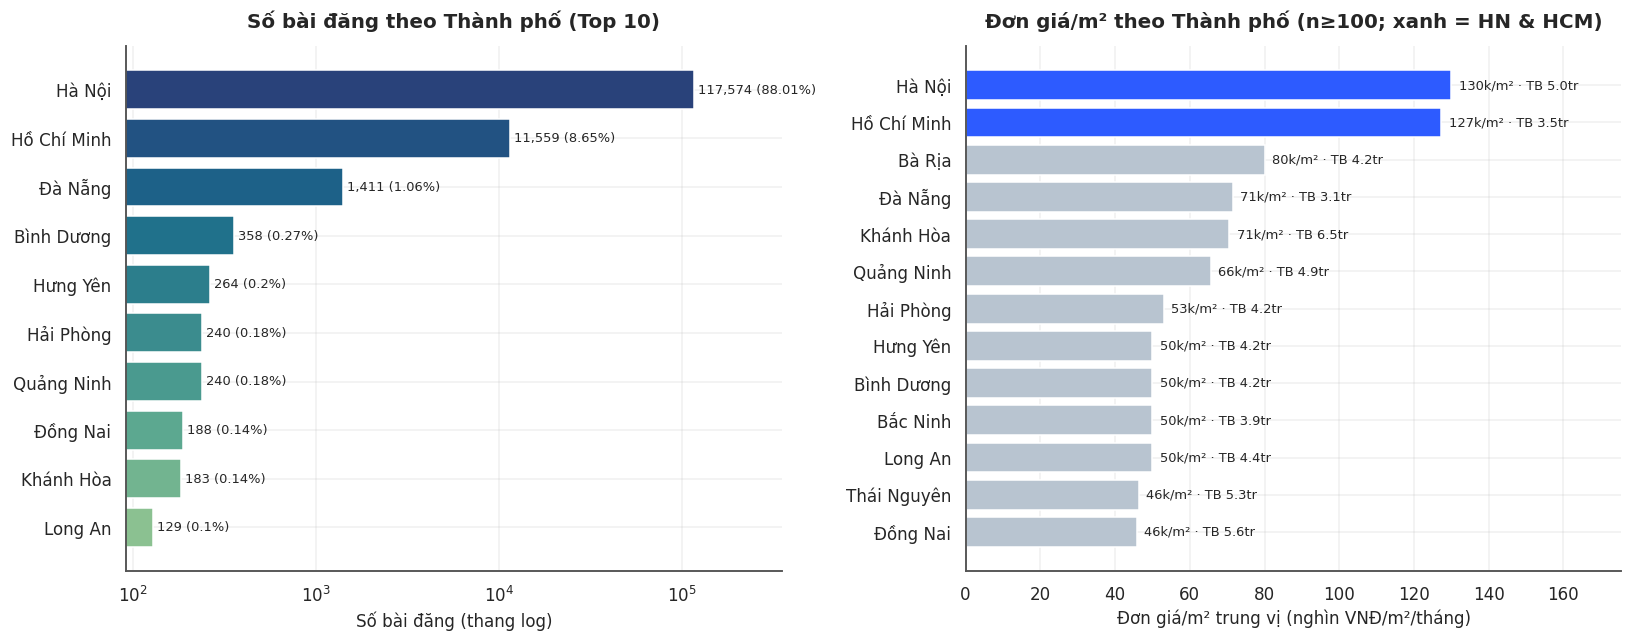

,số bài,giá TB (tr),đơn giá/m² (tr),% dữ liệu
city,,,,
Hà Nội,"117,574",4.96,0.130,88.01
Hồ Chí Minh,"11,559",3.51,0.127,8.65
Đà Nẵng,"1,411",3.12,0.071,1.06
Bình Dương,358,4.19,0.050,0.27
Hưng Yên,264,4.18,0.050,0.20
Hải Phòng,240,4.22,0.053,0.18
Quảng Ninh,240,4.88,0.066,0.18
Đồng Nai,188,5.63,0.046,0.14


→ HN ≈ HCM về đơn giá/m² nhưng giá TUYỆT ĐỐI ở HCM thấp hơn (phòng nhỏ hơn). Các tỉnh khác đơn giá/m² thấp hơn hẳn nhưng mẫu quá ít.


In [6]:
city_stats = (rental.assign(city=rental["city"].fillna("(không rõ)"))
              .groupby("city")
              .agg(n=("price", "size"), gia_TB=("price", "mean"),
                   ppm=("price_per_m2", "median"))
              .sort_values("n", ascending=False))
city_stats["pct"] = (city_stats["n"] / city_stats["n"].sum() * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
# (a) Số bài theo thành phố (thang log vì lệch mạnh)
top = city_stats.head(10).iloc[::-1]
bars = axes[0].barh(top.index, top["n"], color=sns.color_palette("crest", len(top)))
for b, n, p in zip(bars, top["n"], top["pct"]):
    axes[0].text(n * 1.05, b.get_y() + b.get_height()/2, f"{n:,} ({p:g}%)",
                 va="center", fontsize=8.5)
axes[0].set_xscale("log")
axes[0].set_xlabel("Số bài đăng (thang log)")
axes[0].set_title("Số bài đăng theo Thành phố (Top 10)")
axes[0].set_xlim(right=top["n"].max() * 3)

# (b) Đơn giá/m² trung vị theo thành phố (chỉ nơi đủ mẫu n>=100)
pm = (city_stats.query("n >= 100").sort_values("ppm", ascending=False)).iloc[::-1]
colors = [PALETTE[0] if c in ("Hà Nội", "Hồ Chí Minh") else "#B8C4D0" for c in pm.index]
bars = axes[1].barh(pm.index, pm["ppm"] * 1000, color=colors)
for b, v, g in zip(bars, pm["ppm"] * 1000, pm["gia_TB"]):
    axes[1].text(v + 2, b.get_y() + b.get_height()/2, f"{v:.0f}k/m² · TB {g:.1f}tr",
                 va="center", fontsize=8.5)
axes[1].set_xlabel("Đơn giá/m² trung vị (nghìn VNĐ/m²/tháng)")
axes[1].set_title("Đơn giá/m² theo Thành phố (n≥100; xanh = HN & HCM)")
axes[1].set_xlim(right=(pm["ppm"] * 1000).max() * 1.35)
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "01b_city_distribution.png"); plt.show()

display(city_stats.head(8).rename(columns={
    "n": "số bài", "gia_TB": "giá TB (tr)", "ppm": "đơn giá/m² (tr)", "pct": "% dữ liệu"})
    .style.format({"số bài": "{:,.0f}", "giá TB (tr)": "{:.2f}",
                   "đơn giá/m² (tr)": "{:.3f}", "% dữ liệu": "{:.2f}"})
    .background_gradient(subset=["% dữ liệu"], cmap="crest")
    .set_caption("Phân bố & mặt bằng giá theo thành phố"))
print("→ HN ≈ HCM về đơn giá/m² nhưng giá TUYỆT ĐỐI ở HCM thấp hơn (phòng nhỏ hơn). "
      "Các tỉnh khác đơn giá/m² thấp hơn hẳn nhưng mẫu quá ít.")

#### Bản đồ cây (treemap) — phân bố Thành phố → Quận/Huyện — *tương tác*

Ô càng to = càng nhiều bài đăng; màu = đơn giá/m². Bấm vào một thành phố để **đào sâu**
xuống từng quận. Đây là cách trực quan nhất để thấy dữ liệu dồn vào đâu.


In [7]:
tm = (rental.assign(city=rental["city"].fillna("(không rõ)"),
                    district=rental["district"].fillna("(không rõ)"))
      .groupby(["city", "district"])
      .agg(n=("price", "size"), ppm=("price_per_m2", "median")).reset_index())
tm = tm[tm.groupby("city")["n"].transform("sum") >= 100]   # bỏ tỉnh quá ít mẫu

fig = px.treemap(tm, path=[px.Constant("Toàn quốc"), "city", "district"],
                 values="n", color="ppm", color_continuous_scale="Tealgrn",
                 title="Phân bố bài đăng theo Thành phố → Quận/Huyện (kích thước=số bài, màu=đơn giá/m²)")
fig.update_traces(hovertemplate="<b>%{label}</b><br>Số bài: %{value:,}<br>"
                  "Đơn giá/m²: %{color:.3f} tr<extra></extra>")
fig.update_coloraxes(colorbar_title="đơn giá/m²")
show_px(fig, "01c_treemap_city_district", w=1050, h=640)

## 4. Thống kê mô tả (Phân tích đơn biến)

Tính Mean, Median, Std, Min/Max, **Skewness** (độ lệch) và **Kurtosis** (độ nhọn)
cho các biến số — theo Slide L4.


In [8]:
def describe_full(df, cols):
    d = df[cols].describe().T
    d["median"]   = df[cols].median()
    d["skewness"] = df[cols].skew()
    d["kurtosis"] = df[cols].kurt()
    return d[["count", "mean", "std", "min", "25%", "median", "75%", "max",
              "skewness", "kurtosis"]].round(2)

num_cols = ["price", "area", "bedrooms", "bathrooms", "n_features", "price_per_m2"]
desc = describe_full(rental, num_cols)
display(desc.style.format("{:.2f}")
        .background_gradient(subset=["skewness", "kurtosis"], cmap="vlag")
        .set_caption("Thống kê mô tả — tập cho thuê (giá: triệu VNĐ/tháng)"))

,count,mean,std,min,25%,median,75%,max,skewness,kurtosis
price,133586.00,4.80,2.87,0.50,2.90,4.00,6.00,17.00,1.55,2.46
area,133586.00,41.48,27.72,8.00,20.00,30.00,50.00,180.00,1.59,2.35
bedrooms,133586.00,1.51,0.98,0.00,1.00,1.00,2.00,6.00,2.08,4.45
bathrooms,133586.00,1.29,0.73,0.00,1.00,1.00,1.00,5.00,2.89,9.91
n_features,133586.00,6.56,1.94,0.00,5.00,7.00,8.00,12.00,-0.12,-0.20
price_per_m2,133586.00,0.14,0.09,0.00,0.08,0.13,0.18,1.60,1.64,4.84


**Nhận xét:** `price` và `area` **lệch phải nhưng ở mức vừa** (skewness ~0.8–1.2,
không còn đuôi cực đoan vì Bước 2 đã lọc `price ≤ 17`, `area ≤ 180`). Vì vẫn lệch dương,
biến đổi **`log`** giúp phân phối cân đối hơn — sẽ kiểm chứng ở mục 5.2 và là gợi ý cho
mô hình tuyến tính (Ridge/LASSO) ở Bước 4. `price_per_m2` lệch phải mạnh hơn (một số
phòng nhỏ giá cao đẩy đơn giá lên).


## 5. Phân phối biến mục tiêu `price` và biến diện tích `area`

### 5.1. Histogram + KDE — *tĩnh (báo cáo)*

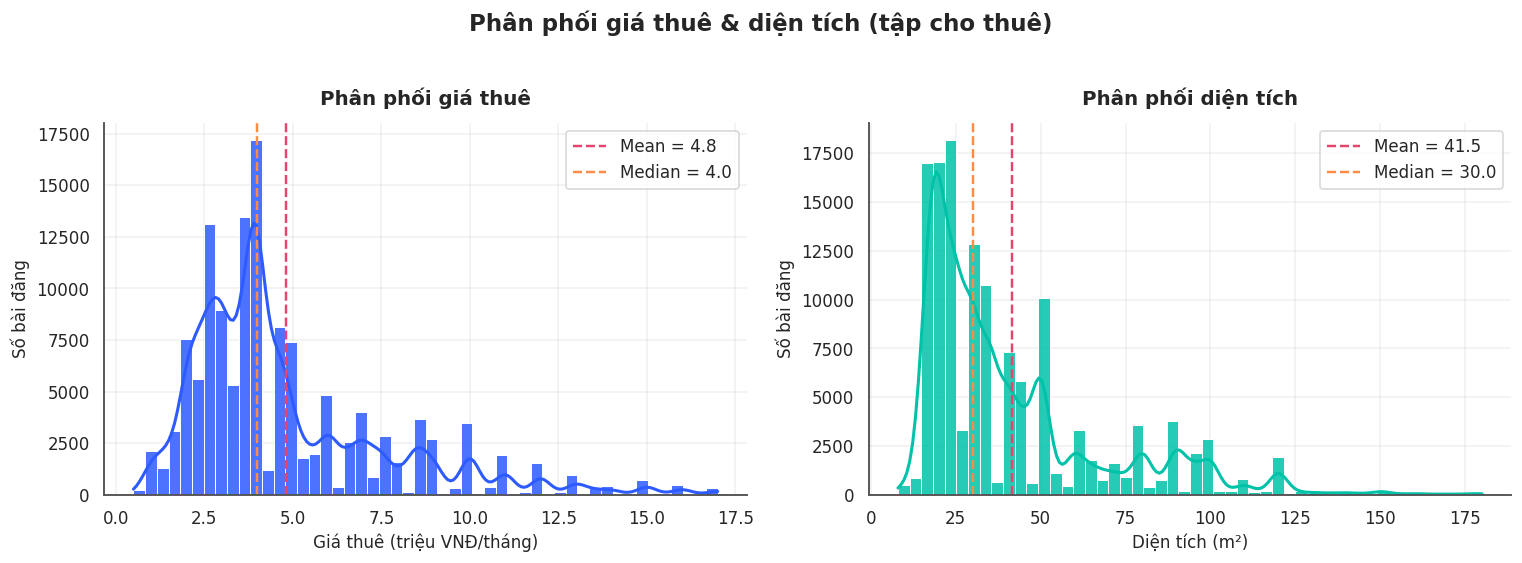

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, color, unit, lab in [
    (axes[0], "price", PALETTE[0], "triệu VNĐ/tháng", "Giá thuê"),
    (axes[1], "area",  PALETTE[1], "m²",              "Diện tích"),
]:
    sns.histplot(rental[col], bins=50, kde=True, color=color,
                 edgecolor="white", alpha=0.85, ax=ax, line_kws={"lw": 2})
    ax.axvline(rental[col].mean(),   color="#E5446D", ls="--", lw=1.6,
               label=f"Mean = {rental[col].mean():.1f}")
    ax.axvline(rental[col].median(), color="#FF8C42", ls="--", lw=1.6,
               label=f"Median = {rental[col].median():.1f}")
    ax.set_xlabel(f"{lab} ({unit})"); ax.set_ylabel("Số bài đăng")
    ax.set_title(f"Phân phối {lab.lower()}")
    ax.legend(frameon=True)
sns.despine(fig)
fig.suptitle("Phân phối giá thuê & diện tích (tập cho thuê)", y=1.02, fontsize=15, fontweight="bold")
plt.tight_layout(); save_mpl(fig, "02_histogram_price_area.png"); plt.show()

### 5.2. Có nên log-transform giá? — so sánh trực tiếp

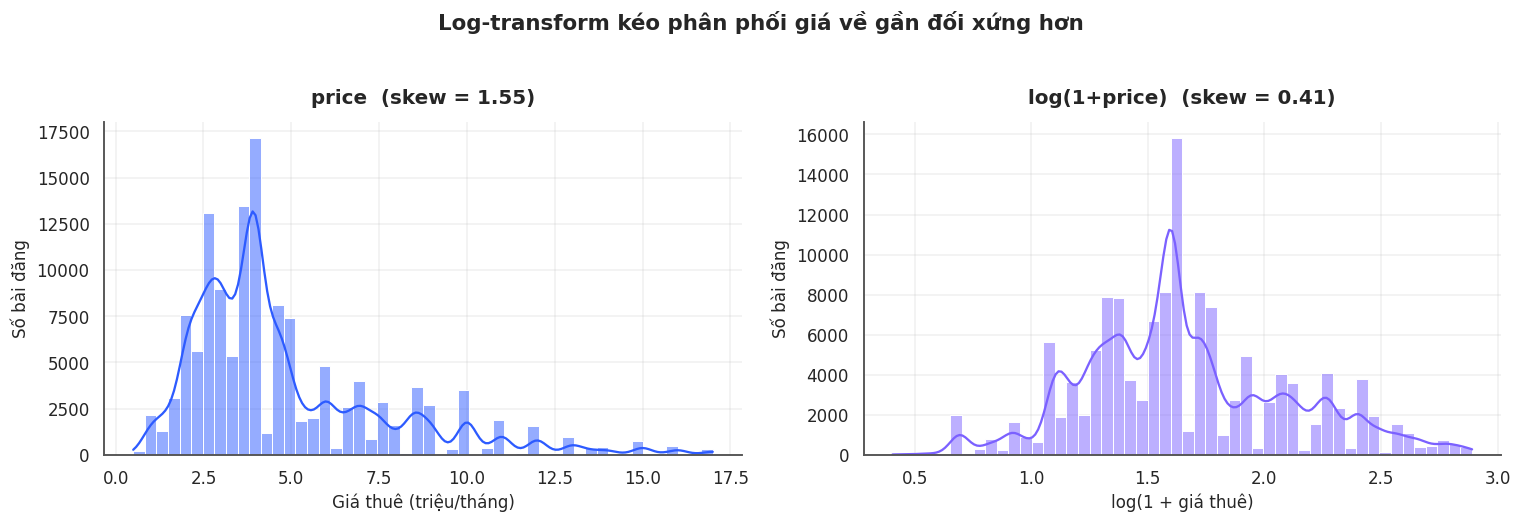

→ Độ lệch giảm sau log → cân nhắc huấn luyện mô hình tuyến tính trên log(price).


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.histplot(rental["price"], bins=50, kde=True, color=PALETTE[0],
             edgecolor="white", ax=axes[0])
axes[0].set_title(f"price  (skew = {rental['price'].skew():.2f})")
axes[0].set_xlabel("Giá thuê (triệu/tháng)"); axes[0].set_ylabel("Số bài đăng")

sns.histplot(rental["log_price"], bins=50, kde=True, color=PALETTE[4],
             edgecolor="white", ax=axes[1])
axes[1].set_title(f"log(1+price)  (skew = {rental['log_price'].skew():.2f})")
axes[1].set_xlabel("log(1 + giá thuê)"); axes[1].set_ylabel("Số bài đăng")
sns.despine(fig)
fig.suptitle("Log-transform kéo phân phối giá về gần đối xứng hơn",
             y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout(); save_mpl(fig, "03_log_transform_price.png"); plt.show()
print("→ Độ lệch giảm sau log → cân nhắc huấn luyện mô hình tuyến tính trên log(price).")

## 6. Phân tích **theo khu vực** — trọng tâm đề tài

Đề tài là *"giá thuê theo khu vực"* nên đây là phần quan trọng nhất: giá khác nhau
thế nào giữa các quận/huyện, và khu nào "đắt đỏ" thực sự khi xét **đơn giá/m²**.


### 6.1. Box Plot — phân tán giá theo Quận/Huyện (Top 12 theo **số bài**) — *tĩnh*

Top 12 quận **nhiều bài đăng nhất** → hầu hết đều ở **Hà Nội** (nơi chiếm phần lớn dữ liệu, xem 3.3).
Đây là so sánh *trong nội bộ Hà Nội*. Muốn xem khu đắt nhất toàn quốc theo đơn giá/m², xem 6.2.


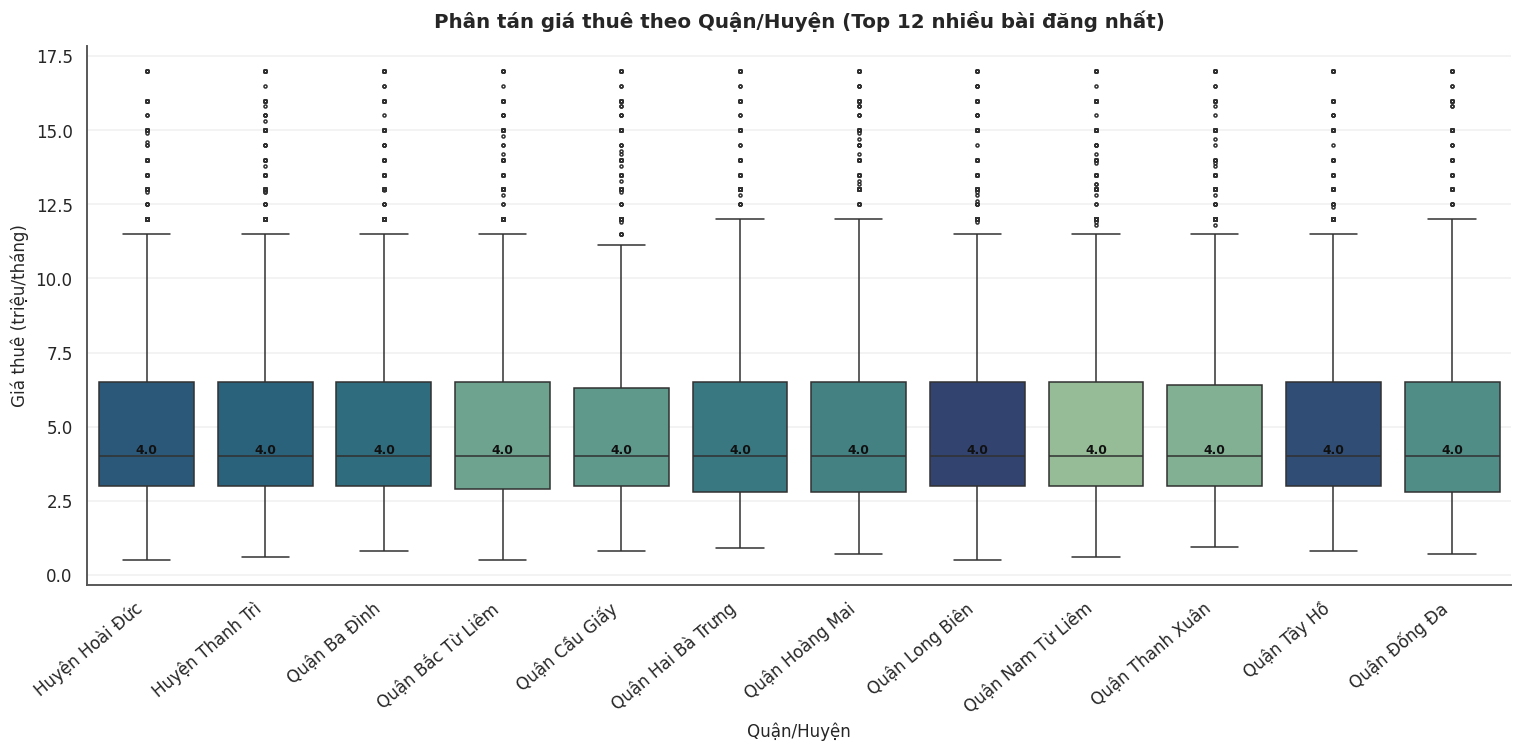

In [11]:
top_districts = rental["district"].value_counts().head(12).index
rt = rental[rental["district"].isin(top_districts)].copy()
order = rt.groupby("district")["price"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(14, 7))
sns.boxplot(data=rt, x="district", y="price", order=order, hue="district",
            palette="crest", legend=False, fliersize=2, ax=ax)
medians = rt.groupby("district")["price"].median().reindex(order)
for i, m in enumerate(medians):
    ax.text(i, m, f"{m:.1f}", ha="center", va="bottom", fontsize=8,
            fontweight="bold", color="#111")
ax.set_xticklabels([t.get_text() for t in ax.get_xticklabels()], rotation=40, ha="right")
ax.set_xlabel("Quận/Huyện"); ax.set_ylabel("Giá thuê (triệu/tháng)")
ax.set_title("Phân tán giá thuê theo Quận/Huyện (Top 12 nhiều bài đăng nhất)")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "04_boxplot_price_by_district.png"); plt.show()

### 6.2. Khu vực nào **đắt nhất theo đơn giá/m²?** — *tĩnh*

Xếp hạng theo đơn giá/m² (công bằng hơn giá tuyệt đối). **Top bị TP.HCM chiếm phần lớn**
vì các quận trung tâm HCM đắt đỏ hơn — *khác hẳn* mục 6.1 (xếp theo số bài → toàn Hà Nội).
Gom theo **(thành phố, quận)** và **tô màu theo thành phố** để thấy rõ mỗi cột thuộc đâu,
đồng thời tránh gộp nhầm các quận trùng tên ở khác tỉnh (vd nhiều nơi đều có "Quận 8").


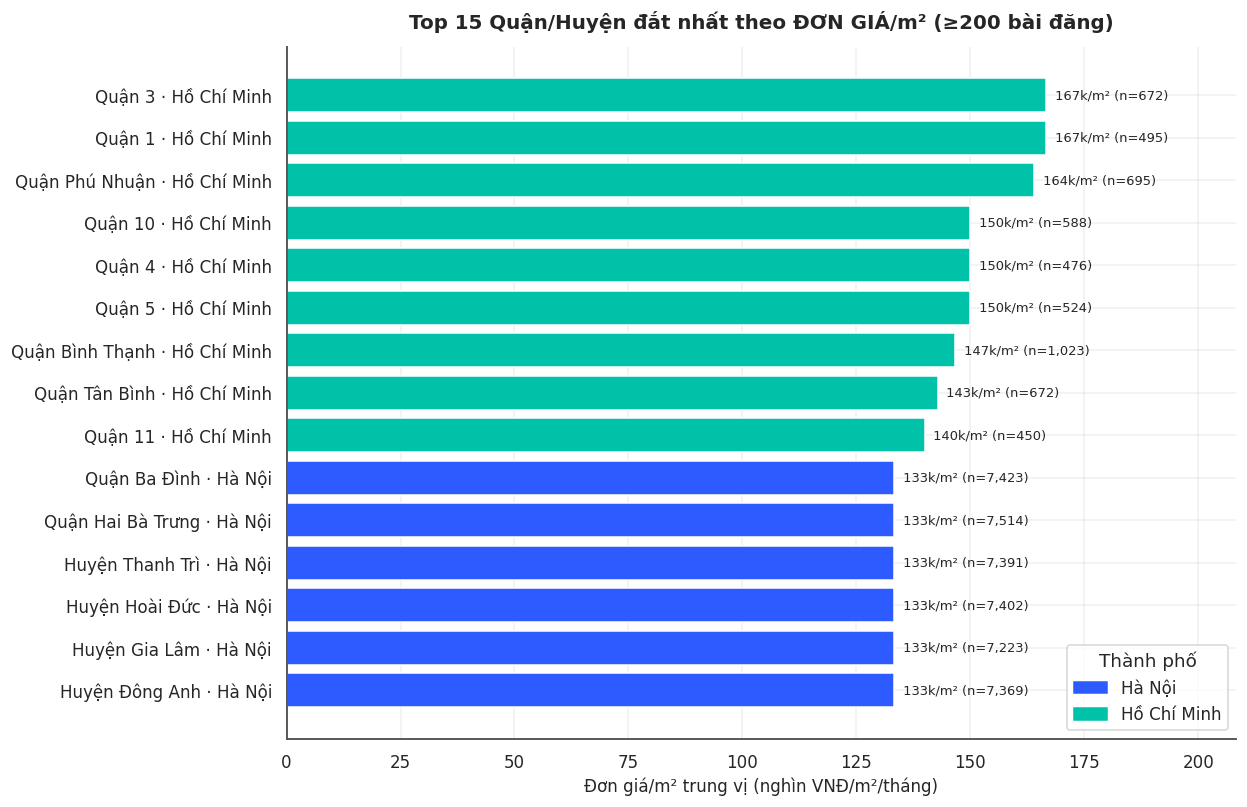

→ TP.HCM trung tâm dẫn đầu đơn giá/m²; Hà Nội góp mặt qua Hoàn Kiếm và vài huyện ven. So với 6.1, đây là lý do hai biểu đồ 'lệch' về hai thành phố khác nhau.


In [12]:
ppm = (rental.dropna(subset=["city", "district"])
       .groupby(["city", "district"])
       .agg(ppm=("price_per_m2", "median"), n=("price_per_m2", "size"))
       .query("n >= 200").sort_values("ppm", ascending=False).head(15).iloc[::-1])

labels = [f"{d} · {c}" for c, d in ppm.index]          # 'Quận 1 · Hồ Chí Minh'
cities = [c for c, d in ppm.index]
cmap = {c: PALETTE[i] for i, c in enumerate(dict.fromkeys(cities))}
colors = [cmap[c] for c in cities]

fig, ax = plt.subplots(figsize=(11.5, 7.5))
bars = ax.barh(labels, ppm["ppm"] * 1000, color=colors)
for b, v, n in zip(bars, ppm["ppm"] * 1000, ppm["n"]):
    ax.text(v + 1, b.get_y() + b.get_height()/2, f" {v:.0f}k/m² (n={n:,})",
            va="center", fontsize=8.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=col) for col in cmap.values()]
ax.legend(handles, cmap.keys(), title="Thành phố", loc="lower right")
ax.set_xlabel("Đơn giá/m² trung vị (nghìn VNĐ/m²/tháng)"); ax.set_ylabel("")
ax.set_xlim(right=(ppm["ppm"] * 1000).max() * 1.25)
ax.set_title("Top 15 Quận/Huyện đắt nhất theo ĐƠN GIÁ/m² (≥200 bài đăng)")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "05_price_per_m2_ranking.png"); plt.show()
print("→ TP.HCM trung tâm dẫn đầu đơn giá/m²; Hà Nội góp mặt qua Hoàn Kiếm và vài huyện ven. "
      "So với 6.1, đây là lý do hai biểu đồ 'lệch' về hai thành phố khác nhau.")

### 6.3. Khám phá giá theo quận — *tương tác (hover xem phân vị)*

In [13]:
fig = px.box(rt, x="district", y="price", category_orders={"district": list(order)},
             color="district", points=False,
             title="Phân phối giá thuê theo Quận/Huyện (kéo/zoom để khám phá)")
fig.update_layout(showlegend=False, xaxis_title="", yaxis_title="Giá thuê (triệu/tháng)",
                  xaxis_tickangle=-40)
show_px(fig, "06_box_price_by_district_interactive", w=1050, h=600)

## 7. Phân tích tiện ích (amenities) — 12 đặc trưng nhị phân

Mỗi bài đăng có 12 cờ tiện ích (máy lạnh, thang máy, bảo vệ 24/24, …). Đây là nhóm
đặc trưng quan trọng cho mô hình dự báo, nên ta xem (a) tiện ích nào **phổ biến** và
(b) tiện ích nào gắn với **chênh lệch giá** lớn nhất.

> ⚠️ **Cảnh báo nguồn gốc dữ liệu (đã kiểm toán ở Bước 2 — notebook `02_data_cleaning.ipynb`, mục 7):**
> đối chiếu dữ liệu thô từng nguồn cho thấy chỉ **5/12 cờ** (máy lạnh, máy giặt, nước nóng,
> bảo vệ 24/24, hầm để xe) có cột gốc thật ở đa số nguồn; **7 cờ còn lại chỉ thật ở
> `phongtro123`/`lozido` (~3% dữ liệu)** và bị *điền ngẫu nhiên* khi gộp nguồn ở Bước 2
> (`chothuenhadattoanvn` + `github_*` không có cờ thật nào — bằng chứng: tỷ-lệ-xuất-hiện
> *trùng khít* giữa các nguồn độc lập). Các thống kê dưới đây mô tả dữ liệu **như-nó-là**;
> khi vào mô hình (Bước 4), các ô chế tác được mask NaN theo cơ chế MNAR và `n_features`
> bị loại khỏi đặc trưng.


### 7.1. Mức độ phổ biến của từng tiện ích

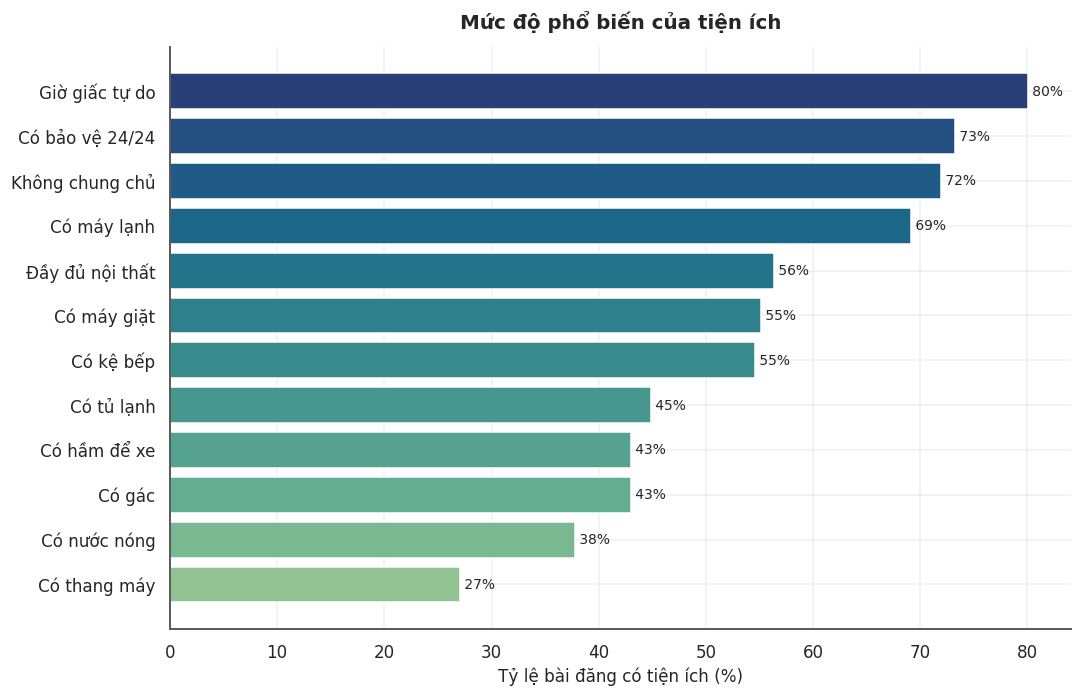

In [14]:
prev = (rental[feature_cols].mean() * 100).sort_values()
labels = [c.replace("feature_", "") for c in prev.index]

fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(labels, prev.values, color=sns.color_palette("crest", len(prev)))
for b, v in zip(bars, prev.values):
    ax.text(v, b.get_y() + b.get_height()/2, f" {v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("Tỷ lệ bài đăng có tiện ích (%)"); ax.set_title("Mức độ phổ biến của tiện ích")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "07_amenity_prevalence.png"); plt.show()

### 7.2. Tiện ích nào gắn với **giá thuê cao hơn?** (chênh lệch giá TB: có − không)

Dùng **trung bình** (median quá thô vì giá hay làm tròn 3/4/5 triệu → chênh lệch hay bằng 0).
Đây là quan hệ **thô (chưa khử nhiễu)** — sẽ thấy ở mục 9.2 rằng thiên lệch nguồn bóp méo nó.


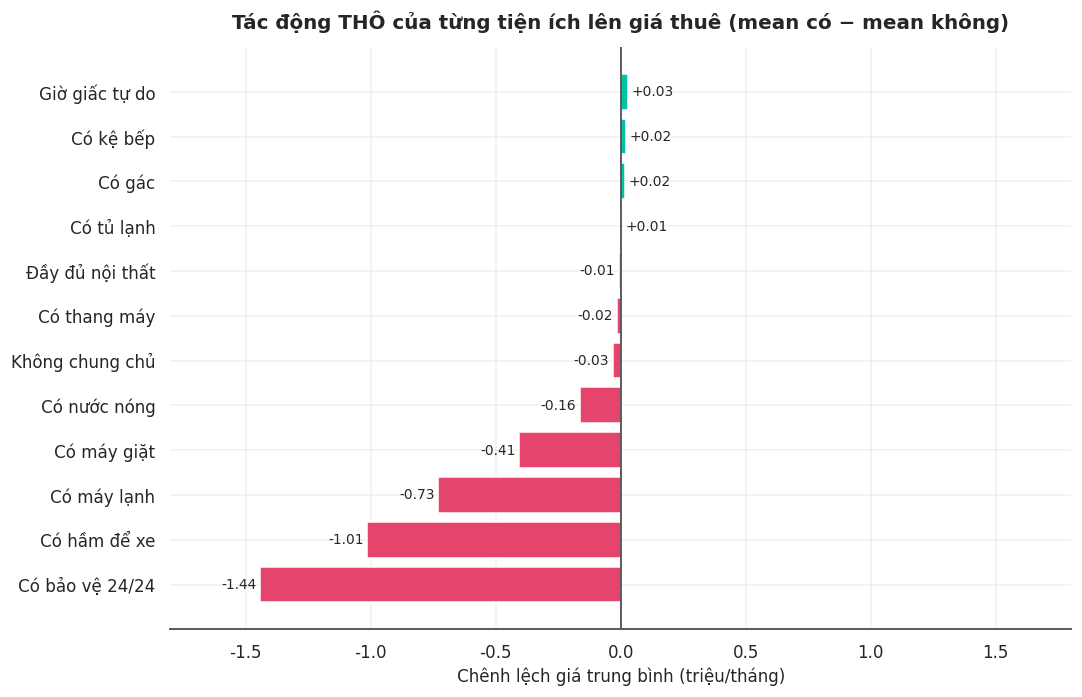

→ Thang máy / hầm để xe / bảo vệ 24/24 gắn với chung cư & giá cao hơn. Một số tiện ích 'cơ bản' lại gắn giá thấp hơn — KHÔNG phải vì tiện ích làm giảm giá mà do thiên lệch nguồn (xem nghịch lý Simpson ở mục 9.2).
→ LƯU Ý: với 7 cờ chế tác (xem cảnh báo đầu mục 7), chênh lệch ở đây gần như chỉ là nhiễu lấy mẫu; còn 5 cờ thật mang cả confound 'tin rẻ quảng cáo tiện ích, căn hộ đắt không liệt kê'. Mô hình Bước 4 xử lý cả hai: mask MNAR + ràng buộc đơn điệu.


In [15]:
rows = []
for c in feature_cols:
    has   = rental.loc[rental[c] == 1, "price"].mean()
    hasnt = rental.loc[rental[c] == 0, "price"].mean()
    rows.append((c.replace("feature_", ""), has - hasnt))
uplift = (pd.DataFrame(rows, columns=["amenity", "diff"]).sort_values("diff"))

fig, ax = plt.subplots(figsize=(10, 6.5))
colors = [PALETTE[3] if v < 0 else PALETTE[1] for v in uplift["diff"]]
bars = ax.barh(uplift["amenity"], uplift["diff"], color=colors)
vmax = uplift["diff"].abs().max()
for b, v in zip(bars, uplift["diff"]):
    ax.text(v + np.sign(v) * vmax * 0.01, b.get_y() + b.get_height()/2,
            f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="#333", lw=1)
ax.set_xlim(-vmax * 1.25, vmax * 1.25)
ax.set_xlabel("Chênh lệch giá trung bình (triệu/tháng)")
ax.set_title("Tác động THÔ của từng tiện ích lên giá thuê (mean có − mean không)")
sns.despine(fig, left=True)
plt.tight_layout(); save_mpl(fig, "08_amenity_price_uplift.png"); plt.show()
print("→ Thang máy / hầm để xe / bảo vệ 24/24 gắn với chung cư & giá cao hơn. Một số tiện ích "
      "'cơ bản' lại gắn giá thấp hơn — KHÔNG phải vì tiện ích làm giảm giá mà do thiên lệch "
      "nguồn (xem nghịch lý Simpson ở mục 9.2).")
print("→ LƯU Ý: với 7 cờ chế tác (xem cảnh báo đầu mục 7), chênh lệch ở đây gần như chỉ là "
      "nhiễu lấy mẫu; còn 5 cờ thật mang cả confound 'tin rẻ quảng cáo tiện ích, căn hộ đắt "
      "không liệt kê'. Mô hình Bước 4 xử lý cả hai: mask MNAR + ràng buộc đơn điệu.")

## 8. Quan hệ song biến: Diện tích / Phòng ngủ ↔ Giá thuê

### 8.1. Mật độ Diện tích ↔ Giá — *tương tác*

Với hơn trăm nghìn bài đăng, biểu đồ điểm bị **chồng lấp** thành đám mây khó đọc. Thay bằng
**bản đồ mật độ (density heatmap)**: mỗi ô tô đậm theo *số bài đăng* rơi vào ô. Do mật độ
**lệch rất mạnh** (vùng lõi đông gấp hàng nghìn lần phần còn lại), ta dùng **thang màu log**
để lộ rõ cả cấu trúc thưa — di chuột để xem số bài thực của từng ô.


In [16]:
import math
cnt, xe, ye = np.histogram2d(rental["area"], rental["price"], bins=[46, 34])
xc, yc = (xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2
z = np.log10(cnt.T + 1)                      # màu theo log; hover hiện số thực
ticks = [1, 10, 50, 200, 1000, 5000]
fig = go.Figure(go.Heatmap(
    x=xc, y=yc, z=z, colorscale="Tealgrn",
    customdata=cnt.T.astype(int),
    colorbar=dict(title="Số bài",
                  tickvals=[math.log10(t + 1) for t in ticks],
                  ticktext=[str(t) for t in ticks]),
    hovertemplate="Diện tích ≈ %{x:.0f} m²<br>Giá ≈ %{y:.1f} triệu<br>"
                  "Số bài: %{customdata}<extra></extra>"))
fig.update_layout(
    title=f"Mật độ Diện tích × Giá thuê — thang màu log (toàn bộ {len(rental):,} bài đăng)",
    xaxis_title="Diện tích (m²)", yaxis_title="Giá thuê (triệu/tháng)")
show_px(fig, "09_density_area_price_interactive", w=980, h=620)
print("Đọc biểu đồ: vệt đậm chéo lên = giá tăng theo diện tích; 'sống' ngang ở giá ≈ 4 triệu "
      "và các vạch dọc ở diện tích tròn (20/25/30 m²) phản ánh thói quen làm tròn khi đăng tin.")

Đọc biểu đồ: vệt đậm chéo lên = giá tăng theo diện tích; 'sống' ngang ở giá ≈ 4 triệu và các vạch dọc ở diện tích tròn (20/25/30 m²) phản ánh thói quen làm tròn khi đăng tin.


### 8.2. Regression Plot — xu hướng tuyến tính — *tĩnh*

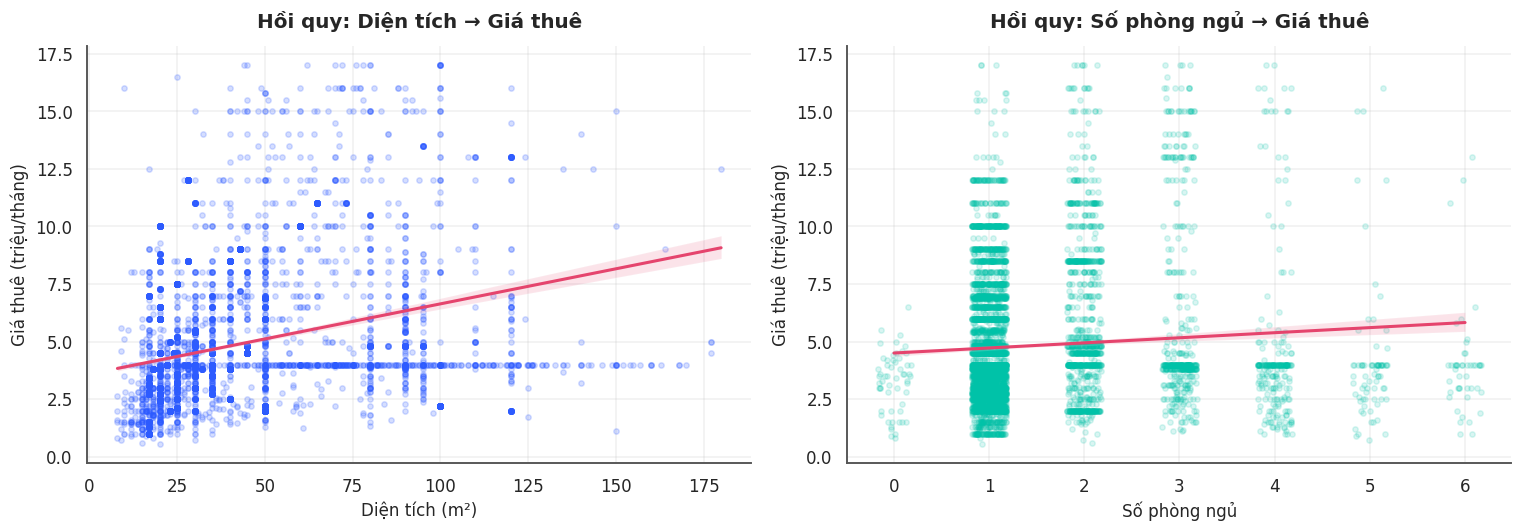

In [17]:
samp = rental.sample(min(6000, len(rental)), random_state=42)   # mẫu nhẹ cho scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=samp, x="area", y="price", ax=axes[0],
            scatter_kws={"alpha": 0.20, "s": 12, "color": PALETTE[0]},
            line_kws={"color": "#E5446D", "lw": 2})
axes[0].set_title("Hồi quy: Diện tích → Giá thuê")
axes[0].set_xlabel("Diện tích (m²)"); axes[0].set_ylabel("Giá thuê (triệu/tháng)")

sns.regplot(data=samp, x="bedrooms", y="price", ax=axes[1], x_jitter=0.18,
            scatter_kws={"alpha": 0.15, "s": 12, "color": PALETTE[1]},
            line_kws={"color": "#E5446D", "lw": 2})
axes[1].set_title("Hồi quy: Số phòng ngủ → Giá thuê")
axes[1].set_xlabel("Số phòng ngủ"); axes[1].set_ylabel("Giá thuê (triệu/tháng)")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "10_regression_plots.png"); plt.show()

## 9. Tương quan giữa các biến

Dùng **cả Pearson (tuyến tính) lẫn Spearman (đơn điệu, bền với lệch/ngoại lệ)** —
vì dữ liệu lệch phải, Spearman thường phản ánh quan hệ thực tế tốt hơn.


### 9.1. Heatmap tương quan Pearson vs Spearman — *tĩnh*

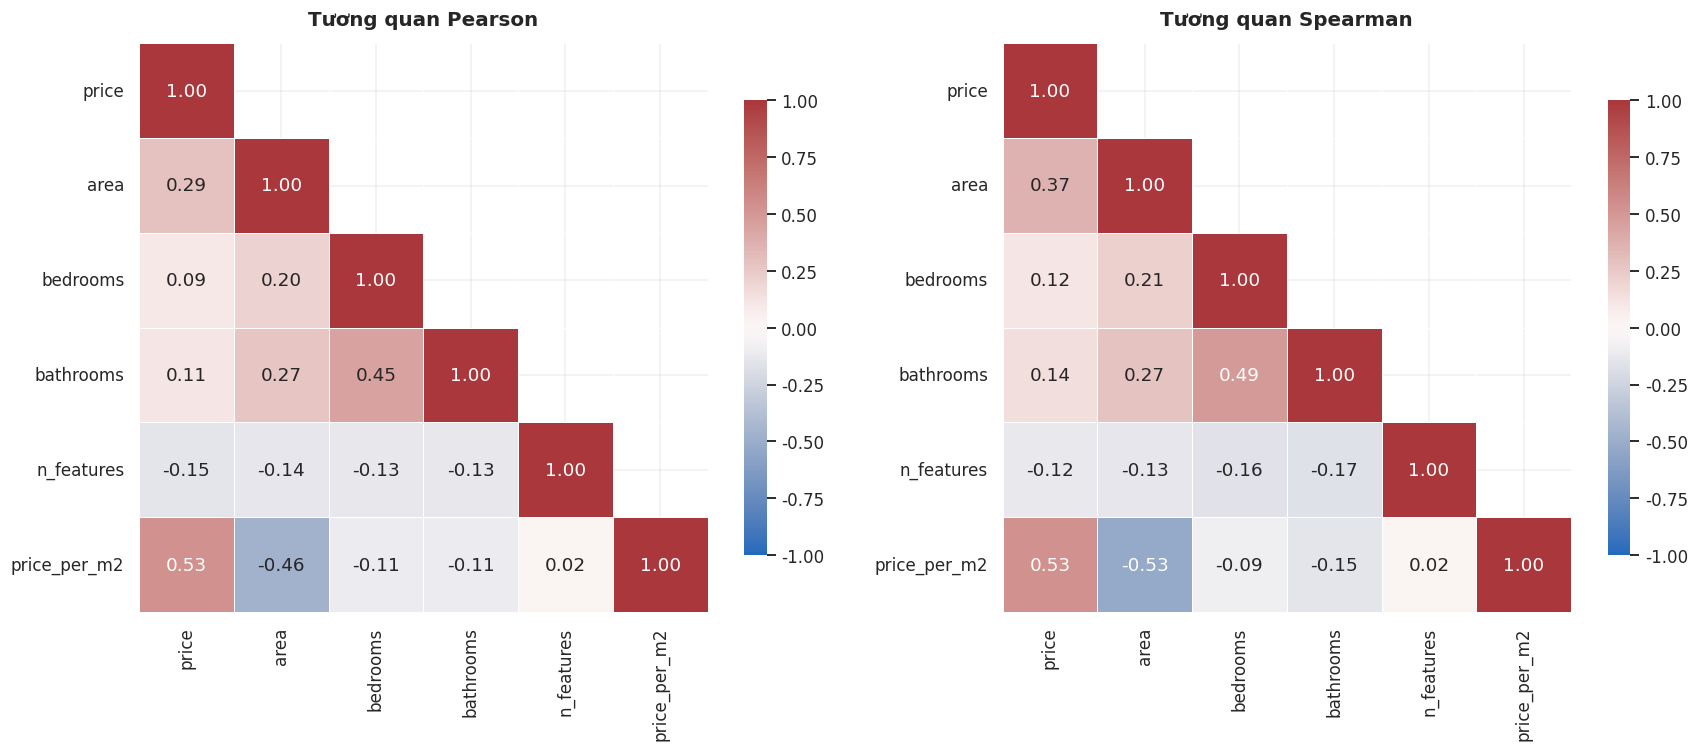

Tương quan với GIÁ THUÊ (Spearman):
price_per_m2    0.532
area            0.366
bathrooms       0.141
bedrooms        0.115
n_features     -0.119


In [18]:
corr_cols = ["price", "area", "bedrooms", "bathrooms", "n_features", "price_per_m2"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = rental[corr_cols].corr(method=method)
    mask = np.triu(np.ones_like(c, dtype=bool), k=1)
    sns.heatmap(c, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
                vmin=-1, vmax=1, square=True, linewidths=0.5,
                cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title(f"Tương quan {method.capitalize()}")
plt.tight_layout(); save_mpl(fig, "11_heatmap_correlation.png"); plt.show()

print("Tương quan với GIÁ THUÊ (Spearman):")
print(rental[corr_cols].corr(method="spearman")["price"]
      .drop("price").sort_values(ascending=False).round(3).to_string())

### 9.2. Điều tra nghịch lý: vì sao `n_features` tương quan **âm** với giá?

Tổng hợp toàn cục cho thấy nhiều tiện ích ↔ giá thấp — phản trực giác. Nghi vấn:
**thiên lệch nguồn** (nguồn giá rẻ lại liệt kê nhiều tiện ích). Ta kiểm bằng cách so
sánh ở **mức nguồn** và tính tương quan **trong từng nguồn** (kiểm soát yếu tố nguồn).


In [19]:
agg = (rental.groupby("source")
       .agg(n=("price", "size"), gia_TB=("price", "mean"),
            tien_ich_TB=("n_features", "mean")).query("n >= 500").reset_index())

fig = px.scatter(agg, x="tien_ich_TB", y="gia_TB", size="n", color="source",
                 text="source", size_max=55,
                 title="Mức NGUỒN: nguồn nhiều tiện ích lại có giá trung bình thấp (nghịch lý Simpson)")
fig.update_traces(textposition="top center", textfont_size=10)
fig.update_layout(xaxis_title="Số tiện ích trung bình / bài",
                  yaxis_title="Giá thuê trung bình (triệu/tháng)", showlegend=False)
show_px(fig, "12_simpson_source_paradox", w=1000, h=600)

# Tương quan n_features↔price TRONG từng nguồn lớn (khử nhiễu nguồn)
print("Tương quan Spearman(n_features, price) TRONG từng nguồn (≥2.000 bài):")
for s, g in rental.groupby("source"):
    if len(g) >= 2000:
        print(f"  {s:22s} r = {g['n_features'].corr(g['price'], method='spearman'):+.3f}  (n={len(g):,})")
print("\n→ Quan hệ âm toàn cục chủ yếu do THIÊN LỆCH NGUỒN, không phải tiện ích làm giảm giá.")
print("→ Các hệ số ≈ 0 TUYỆT ĐỐI ở nhiều nguồn (ctndtvn, github_*) chính là manh mối đã được "
      "kiểm toán ở BƯỚC 2 (notebook 02): cờ tiện ích của các nguồn đó bị ĐIỀN NGẪU NHIÊN khi "
      "gộp (biến ngẫu nhiên độc lập ⇒ tương quan 0 với mọi thứ).")
print("→ Hệ quả cho mô hình (Bước 4): loại 'source' (artifact thu thập), loại 'n_features' "
      "(tổng của cờ chế tác), mask MNAR các ô chế tác, và ràng buộc đơn điệu 12 cờ tiện ích.")

Tương quan Spearman(n_features, price) TRONG từng nguồn (≥2.000 bài):
  chothuenhadattoanvn    r = +0.013  (n=9,866)
  chothuephongtro        r = -0.039  (n=95,086)
  github_hcm             r = -0.007  (n=8,771)
  github_hn              r = -0.003  (n=2,879)
  nhatot                 r = -0.100  (n=9,920)
  phongtro123            r = +0.212  (n=2,663)

→ Quan hệ âm toàn cục chủ yếu do THIÊN LỆCH NGUỒN, không phải tiện ích làm giảm giá.
→ Các hệ số ≈ 0 TUYỆT ĐỐI ở nhiều nguồn (ctndtvn, github_*) chính là manh mối đã được kiểm toán ở BƯỚC 2 (notebook 02): cờ tiện ích của các nguồn đó bị ĐIỀN NGẪU NHIÊN khi gộp (biến ngẫu nhiên độc lập ⇒ tương quan 0 với mọi thứ).
→ Hệ quả cho mô hình (Bước 4): loại 'source' (artifact thu thập), loại 'n_features' (tổng của cờ chế tác), mask MNAR các ô chế tác, và ràng buộc đơn điệu 12 cờ tiện ích.


## 10. Phân cụm K-Means — phân khúc thị trường

Gom cụm trên `price`, `area`, `n_features` (chuẩn hóa Z-score). Chọn K bằng **Elbow**
*kết hợp* **Silhouette** (đo độ tách cụm) thay vì chỉ nhìn khuỷu tay.


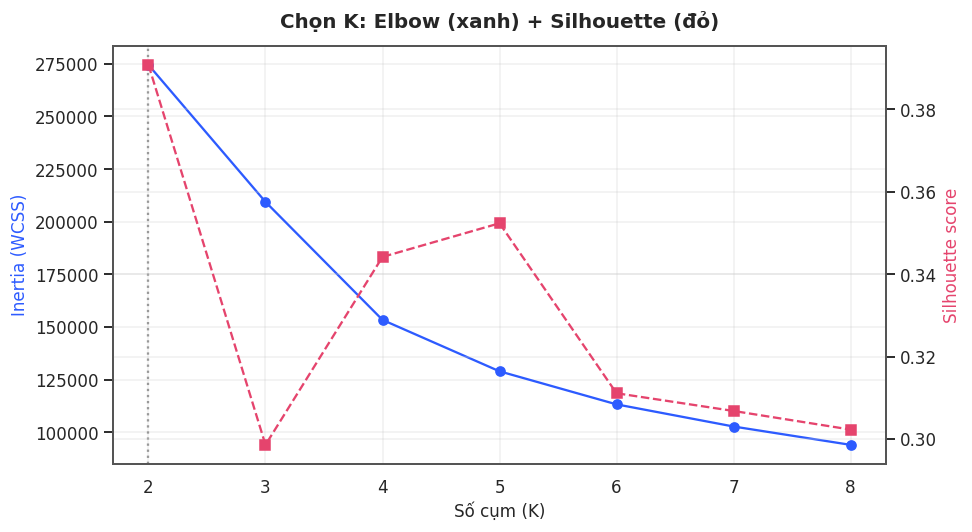

Silhouette cao nhất tại K = 2. Chọn K = 4 cho diễn giải phân khúc rõ ràng.


In [20]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

feat = rental[["price", "area", "n_features"]].dropna()
X = StandardScaler().fit_transform(feat)
sil_idx = np.random.RandomState(42).choice(len(X), min(10000, len(X)), replace=False)

K_range = range(2, 9)
inertias, sils = [], []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X[sil_idx], km.labels_[sil_idx]))

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(list(K_range), inertias, "o-", color=PALETTE[0], label="Inertia (WCSS)")
ax1.set_xlabel("Số cụm (K)"); ax1.set_ylabel("Inertia (WCSS)", color=PALETTE[0])
ax2 = ax1.twinx()
ax2.plot(list(K_range), sils, "s--", color=PALETTE[3], label="Silhouette")
ax2.set_ylabel("Silhouette score", color=PALETTE[3])
ax1.set_title("Chọn K: Elbow (xanh) + Silhouette (đỏ)")
best_k = list(K_range)[int(np.argmax(sils))]
ax1.axvline(best_k, color="#999", ls=":", lw=1.5)
plt.tight_layout(); save_mpl(fig, "13_kmeans_elbow_silhouette.png"); plt.show()
print(f"Silhouette cao nhất tại K = {best_k}. Chọn K = 4 cho diễn giải phân khúc rõ ràng.")

### 10.1. Trực quan & hồ sơ các phân khúc

,gia_TB,dt_TB,tien_ich_TB,so_luong,phan_khuc
cluster,,,,,
2,3.8,29,5.0,"42,738",Bình dân/nhỏ
0,3.9,29,8.2,"55,896",Phổ thông
3,4.3,97,6.1,"16,983",Khá/rộng
1,10.6,56,5.7,"17,969",Cao cấp/rộng


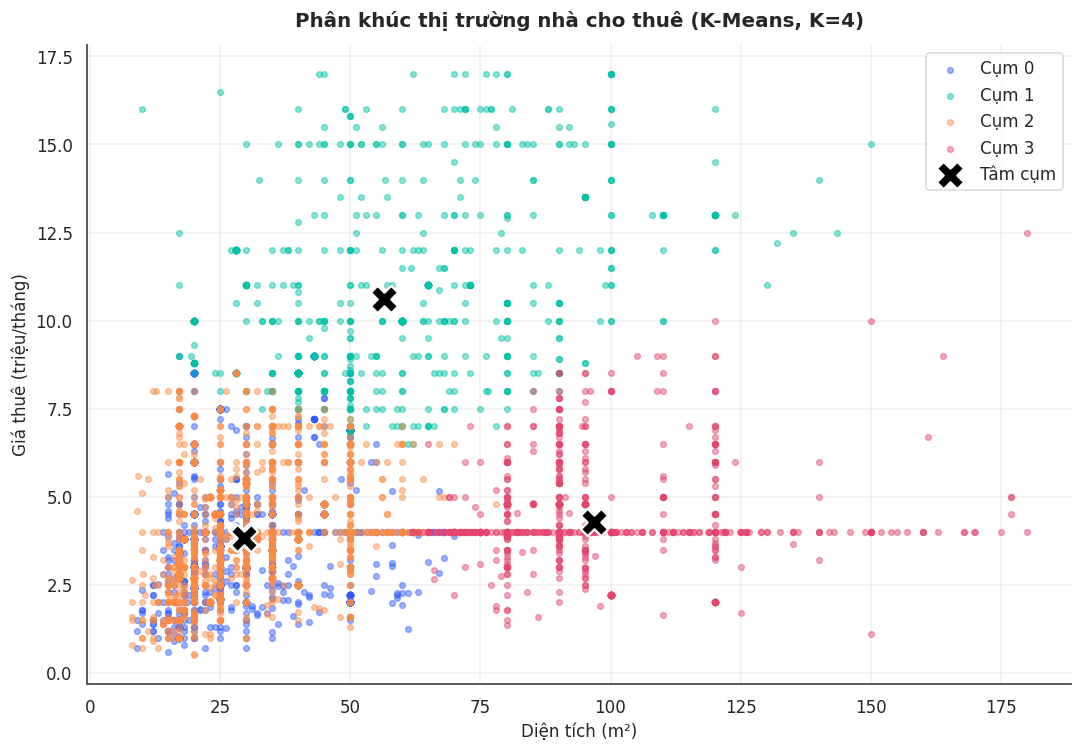

In [21]:
K = 4
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X)
feat = feat.assign(cluster=km.labels_)

# Hồ sơ trung bình mỗi cụm + đặt tên gợi nhớ
profile = (feat.groupby("cluster")
           .agg(gia_TB=("price", "mean"), dt_TB=("area", "mean"),
                tien_ich_TB=("n_features", "mean"), so_luong=("price", "size"))
           .round(2).sort_values("gia_TB"))
names = ["Bình dân/nhỏ", "Phổ thông", "Khá/rộng", "Cao cấp/rộng"][:K]
profile["phan_khuc"] = names
display(profile.style.format({"gia_TB": "{:.1f}", "dt_TB": "{:.0f}",
        "tien_ich_TB": "{:.1f}", "so_luong": "{:,.0f}"})
        .background_gradient(subset=["gia_TB"], cmap="crest")
        .set_caption(f"Hồ sơ {K} phân khúc thị trường nhà cho thuê"))

# Scatter cụm + tâm cụm (tĩnh)
scaler = StandardScaler().fit(rental[["price", "area", "n_features"]].dropna())
centers = scaler.inverse_transform(km.cluster_centers_)
samp_c = feat.sample(min(7000, len(feat)), random_state=42)
fig, ax = plt.subplots(figsize=(10, 7))
pal = sns.color_palette(PALETTE, K)
for c in range(K):
    d = samp_c[samp_c["cluster"] == c]
    ax.scatter(d["area"], d["price"], s=14, alpha=0.45, color=pal[c], label=f"Cụm {c}")
ax.scatter(centers[:, 1], centers[:, 0], s=320, marker="X",
           c="black", edgecolor="white", linewidth=1.5, zorder=5, label="Tâm cụm")
ax.set_xlabel("Diện tích (m²)"); ax.set_ylabel("Giá thuê (triệu/tháng)")
ax.set_title(f"Phân khúc thị trường nhà cho thuê (K-Means, K={K})")
ax.legend(); sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "14_kmeans_clusters.png"); plt.show()

## 11. PCA — giảm chiều dữ liệu đa biến

Chiếu 5 biến số (`price, area, bedrooms, bathrooms, n_features`) xuống 2D để kiểm tra
cấu trúc tuyến tính, kèm **biplot** diễn giải ý nghĩa mỗi thành phần chính.


Phương sai giải thích: PC1=36.4%, PC2=21.2%, tổng=57.6%


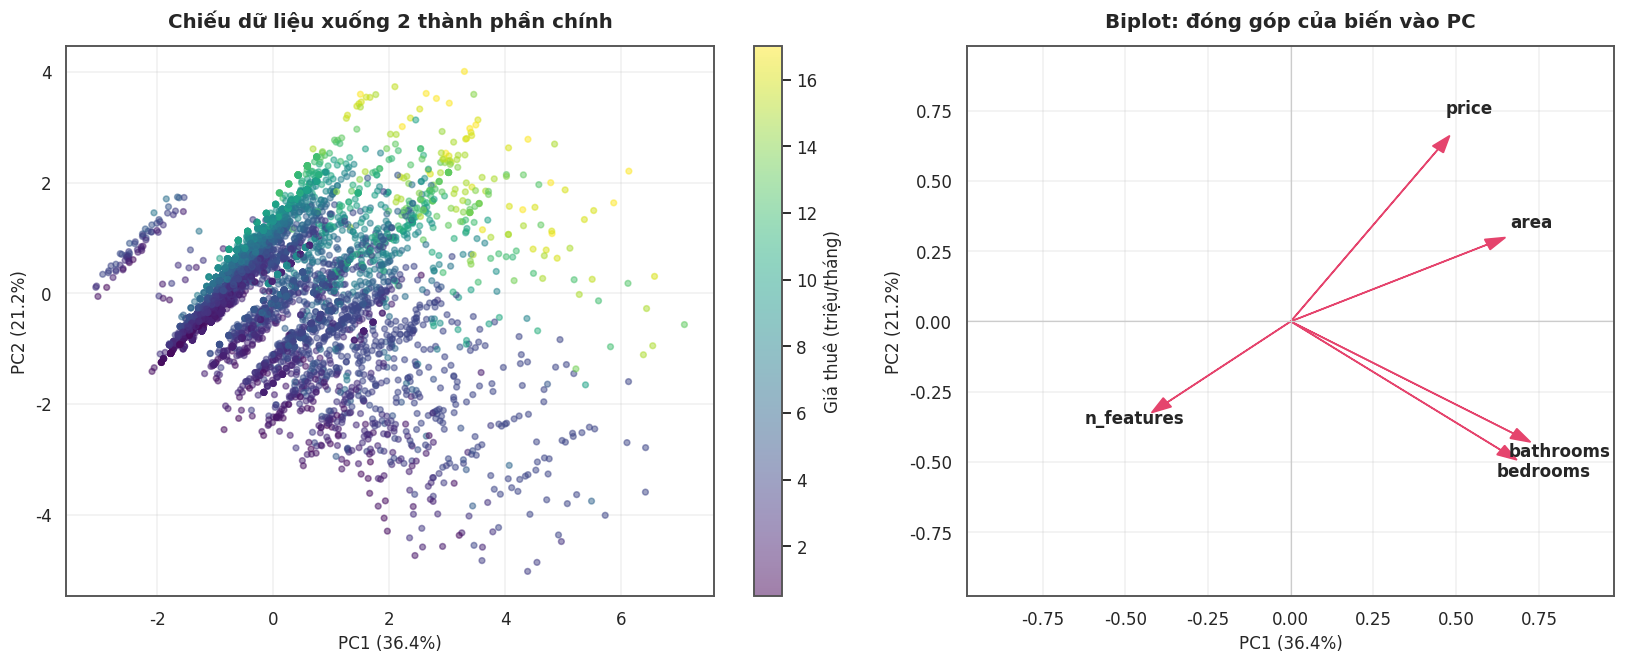

→ PC1 phản ánh 'quy mô' (diện tích + số phòng + giá cùng tăng); PC2 phân tách theo tiện ích/đơn giá. Cấu trúc tuyến tính rõ → phù hợp cả mô hình tuyến tính (Ridge/LASSO) lẫn phi tuyến (Random Forest/XGBoost).


In [22]:
from sklearn.decomposition import PCA

pca_cols = ["price", "area", "bedrooms", "bathrooms", "n_features"]
multi = rental[pca_cols].dropna()
Xs = StandardScaler().fit_transform(multi)
pca = PCA(n_components=2).fit(Xs)
pcs = pca.transform(Xs)
evr = pca.explained_variance_ratio_
print(f"Phương sai giải thích: PC1={evr[0]:.1%}, PC2={evr[1]:.1%}, tổng={evr[:2].sum():.1%}")

idx = np.random.RandomState(42).choice(len(pcs), min(7000, len(pcs)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2),
                         gridspec_kw={"width_ratios": [1.25, 1]})
# (a) Chiếu 2D tô màu theo giá
sc = axes[0].scatter(pcs[idx, 0], pcs[idx, 1], c=multi["price"].values[idx],
                     cmap="viridis", alpha=0.5, s=14)
fig.colorbar(sc, ax=axes[0], label="Giá thuê (triệu/tháng)")
axes[0].set_xlabel(f"PC1 ({evr[0]:.1%})"); axes[0].set_ylabel(f"PC2 ({evr[1]:.1%})")
axes[0].set_title("Chiếu dữ liệu xuống 2 thành phần chính")

# (b) Biplot loadings — diễn giải PC
load = pca.components_.T * np.sqrt(pca.explained_variance_)
for i, var in enumerate(pca_cols):
    axes[1].arrow(0, 0, load[i, 0], load[i, 1], color=PALETTE[3],
                  head_width=0.04, length_includes_head=True)
    axes[1].text(load[i, 0]*1.12, load[i, 1]*1.12, var, ha="center",
                 fontsize=11, fontweight="bold")
lim = np.abs(load).max() * 1.35
axes[1].set_xlim(-lim, lim); axes[1].set_ylim(-lim, lim)
axes[1].axhline(0, color="#ccc", lw=0.8); axes[1].axvline(0, color="#ccc", lw=0.8)
axes[1].set_xlabel(f"PC1 ({evr[0]:.1%})"); axes[1].set_ylabel(f"PC2 ({evr[1]:.1%})")
axes[1].set_title("Biplot: đóng góp của biến vào PC")
plt.tight_layout(); save_mpl(fig, "15_pca_2d_biplot.png"); plt.show()
print("→ PC1 phản ánh 'quy mô' (diện tích + số phòng + giá cùng tăng); "
      "PC2 phân tách theo tiện ích/đơn giá. Cấu trúc tuyến tính rõ → phù hợp cả mô hình "
      "tuyến tính (Ridge/LASSO) lẫn phi tuyến (Random Forest/XGBoost).")

## 12. Tổng kết các khám phá (Insights)

1. **Chất lượng & nguồn dữ liệu:** Dữ liệu tích hợp từ nhiều nguồn nhưng **mất cân bằng nặng**
   (một nguồn chiếm ~71%). Trường `posted_date` có ~46% giá trị tương lai (sentinel cào) →
   không dùng cho phân tích thời gian. `price`/`area` đã được **lọc ngưỡng** ở Bước 2 nên
   không còn ngoại lệ cực đoan.

2. **Phân phối mục tiêu:** `price` lệch phải vừa phải; **log(price)** đưa về gần đối xứng →
   nên cân nhắc huấn luyện mô hình tuyến tính trên thang log (Bước 4).

3. **Yếu tố khu vực (lõi đề tài):** Giá thuê và **đơn giá/m²** khác biệt rõ giữa các quận
   → `district`/`city` là đặc trưng dự báo mạnh. Xếp hạng theo **đơn giá/m²** phản ánh độ
   "đắt đỏ" công bằng hơn giá tuyệt đối. **Lưu ý mất cân bằng địa lý** (mục 3.3): phần lớn dữ
   liệu là Hà Nội, kế đến HCM → top "nhiều bài" là Hà Nội còn top "đắt/m²" là HCM trung tâm;
   kết luận chủ yếu áp dụng cho Hà Nội, các tỉnh khác thiếu mẫu để dự báo riêng.

4. **Diện tích là yếu tố mạnh nhất:** `area` tương quan dương rõ với `price`; `price_per_m2`
   ↔ `area` **âm** → **lợi thế quy mô** (phòng càng rộng đơn giá/m² càng rẻ).

5. **Tiện ích:** Thang máy/hầm xe/bảo vệ 24/24 gắn với giá cao hơn. Tương quan **âm** giữa
   `n_features` và giá ở mức toàn cục là **nghịch lý Simpson do thiên lệch nguồn** — trong
   từng nguồn quan hệ không còn âm. ⚠️ Sâu hơn: **kiểm toán Bước 2** đã chứng minh 7/12 cờ bị
   *điền ngẫu nhiên* khi gộp nguồn ⇒ Bước 4 loại `source` & `n_features`, mask MNAR, ràng
   buộc đơn điệu 12 cờ.

6. **Phân khúc thị trường:** K-Means (K=4) tách rõ 4 phân khúc từ *bình dân/nhỏ* đến
   *cao cấp/rộng*, hữu ích cho định vị sản phẩm trong app demo (Bước 6).

7. **PCA:** 2 thành phần đầu giải thích phần lớn phương sai; PC1 ≈ "quy mô" — dữ liệu có
   cấu trúc tuyến tính rõ, phù hợp cả mô hình tuyến tính lẫn phi tuyến.

> 📦 Biểu đồ tĩnh (PNG) lưu tại `v2/docs/eda/` cho báo cáo PDF; biểu đồ tương tác (HTML)
> tại `v2/docs/eda/interactive/`.
